# NeuroStartup: previsão de cancelamento de clientes (Telco Churn)
**Cliente:** time de retenção de uma operadora de telecom.
**Pedido:** "Quais clientes vão cancelar? Queremos ligar para eles com uma oferta antes que saiam."
**Dados:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn
(baixe o arquivo `WA_Fn-UseC_-Telco-Customer-Churn.csv` e coloque na mesma pasta deste notebook)

In [2]:
# Imports e semente
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, recall_score, precision_score

SEED = 42
keras.utils.set_random_seed(SEED)

## 1 · Conhecer os dados

In [3]:
# Carregar e limpar
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
# TotalCharges tem valores vazios (clientes novos, tenure = 0): viram 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop(columns=["customerID"])           # identificador não ajuda a prever
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(df.shape)
print(f"Taxa de cancelamento: {df['Churn'].mean():.1%}")
df.head()

(7043, 20)
Taxa de cancelamento: 26.5%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


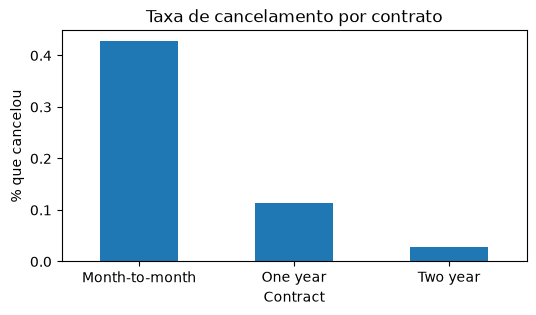

In [4]:
# Gráfico 1: cancelamento por tipo de contrato
df.groupby("Contract")["Churn"].mean().plot(kind="bar", figsize=(6, 3), title="Taxa de cancelamento por contrato")
plt.ylabel("% que cancelou"); plt.xticks(rotation=0); plt.show()
# CONCLUSÃO (edite com suas palavras): clientes com contrato mensal cancelam muito mais que os de contrato anual.

In [ ]:
# **Conclusão:** clientes com contrato mensal cancelam muito mais do que os de contrato de 1 ou 2 anos, então o tipo de contrato é um forte sinal de risco.

SyntaxError: invalid syntax (708715802.py, line 1)

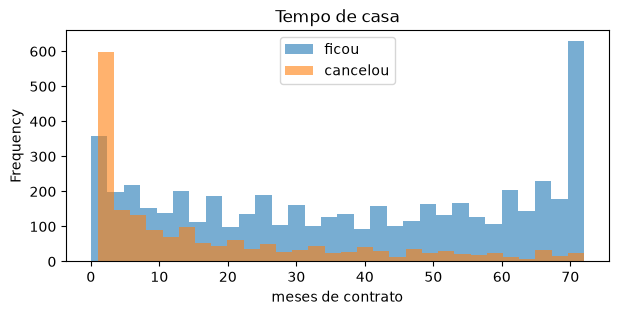

In [5]:
# Gráfico 2: tempo de casa × cancelamento
df[df.Churn == 0]["tenure"].plot(kind="hist", bins=30, alpha=0.6, label="ficou", figsize=(7, 3))
df[df.Churn == 1]["tenure"].plot(kind="hist", bins=30, alpha=0.6, label="cancelou")
plt.xlabel("meses de contrato"); plt.legend(); plt.title("Tempo de casa"); plt.show()
# CONCLUSÃO (edite): quem cancela costuma ser cliente novo, nos primeiros meses.

In [17]:
# **Conclusão:** quem cancela costuma ser cliente novo, concentrado nos primeiros meses de contrato.

In [6]:
# Separação treino / validação / teste (estratificada, por causa do desbalanceamento)
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True).astype(float)
y = df["Churn"].values
COLUNAS = list(X.columns)

X_resto, X_teste, y_resto, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)   # 🔒 cofre
X_treino, X_valid, y_treino, y_valid = train_test_split(X_resto, y_resto, test_size=0.25, random_state=SEED, stratify=y_resto)

escala = StandardScaler().fit(X_treino)         # ajustado SÓ no treino
X_treino_e, X_valid_e, X_teste_e = escala.transform(X_treino), escala.transform(X_valid), escala.transform(X_teste)
print("Treino:", X_treino_e.shape, "| Validação:", X_valid_e.shape, "| Teste:", X_teste_e.shape)

Treino: (4225, 30) | Validação: (1409, 30) | Teste: (1409, 30)


## 2 · Baseline × rede
Como só ~27% cancelam, acurácia engana. Medimos **AUC, recall e precisão**.

In [7]:
# Função de métricas
def metricas(y_real, prob, limiar=0.5):
    pred = (prob >= limiar).astype(int)
    return {"auc": round(roc_auc_score(y_real, prob), 3),
            "recall": round(recall_score(y_real, pred), 3),
            "precisao": round(precision_score(y_real, pred), 3)}

In [8]:
# Baseline: regressão logística
base = LogisticRegression(class_weight="balanced", max_iter=1000).fit(X_treino_e, y_treino)
m_base = metricas(y_valid, base.predict_proba(X_valid_e)[:, 1])
print("Baseline (validação):", m_base)

Baseline (validação): {'auc': 0.836, 'recall': 0.789, 'precisao': 0.514}


In [9]:
# Testar 3 redes e registrar no experimentos.csv
pesos = dict(enumerate(compute_class_weight("balanced", classes=np.unique(y_treino), y=y_treino)))
registros, redes, historicos = [], {}, {}

for neuronios in [16, 32, 64]:
    keras.utils.set_random_seed(SEED)
    rede = keras.Sequential([
        keras.Input(shape=(X_treino_e.shape[1],)),
        layers.Dense(neuronios, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(neuronios // 2, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    rede.compile(optimizer="adam", loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    parada = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=10, restore_best_weights=True)
    hist = rede.fit(X_treino_e, y_treino, validation_data=(X_valid_e, y_valid), epochs=200,
                    batch_size=64, class_weight=pesos, verbose=0, callbacks=[parada])
    m = metricas(y_valid, rede.predict(X_valid_e, verbose=0).ravel())
    registros.append({"neuronios": neuronios, "epocas": len(hist.history["loss"]),
                      "auc_validacao": m["auc"], "recall_validacao": m["recall"], "precisao_validacao": m["precisao"]})
    redes[neuronios], historicos[neuronios] = rede, hist

experimentos = pd.DataFrame(registros)
experimentos.to_csv("experimentos.csv", index=False)
print(experimentos.to_string(index=False))

 neuronios  epocas  auc_validacao  recall_validacao  precisao_validacao
        16      60          0.827             0.644               0.584
        32      25          0.836             0.765               0.537
        64      21          0.833             0.743               0.535


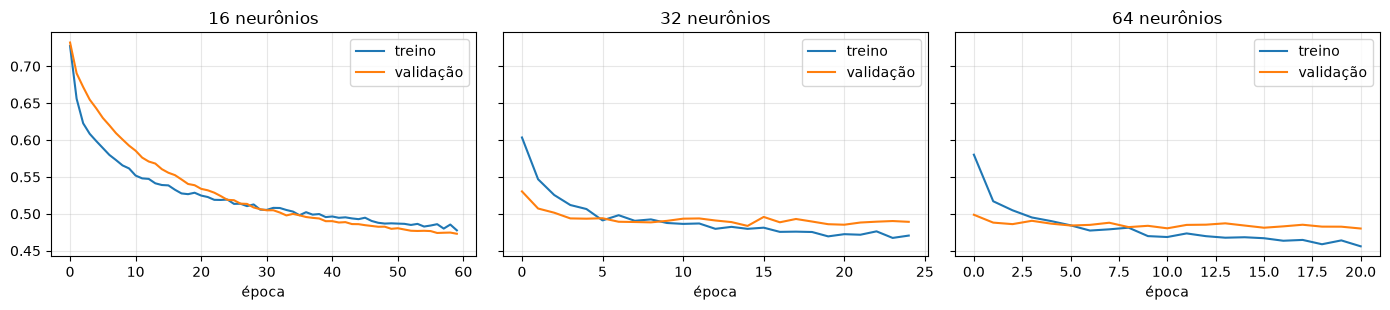

In [10]:
# Curvas de aprendizado
fig, axs = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, (n, h) in zip(axs, historicos.items()):
    ax.plot(h.history["loss"], label="treino"); ax.plot(h.history["val_loss"], label="validação")
    ax.set_title(f"{n} neurônios"); ax.set_xlabel("época"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
# LEITURA (edite): validação parou de cair → early stopping guardou a melhor versão.

In [ ]:
# **Leitura das curvas:** nas três redes, o erro de treino continuou caindo, mas o de validação parou de melhorar depois de algumas épocas. O early stopping interrompeu o treino nesse ponto e restaurou os pesos da melhor época, evitando overfitting.

## 3 · Abrir o cofre (uma única vez!)

In [12]:
# Teste final
melhor_n = int(experimentos.sort_values("auc_validacao", ascending=False).iloc[0]["neuronios"])
melhor = redes[melhor_n]
prob_teste = melhor.predict(X_teste_e, verbose=0).ravel()
m_rede = metricas(y_teste, prob_teste)
m_base_t = metricas(y_teste, base.predict_proba(X_teste_e)[:, 1])
print("Melhor arquitetura:", melhor_n, "neurônios")
print("TESTE → baseline:", m_base_t)
print("TESTE → rede    :", m_rede)

cancelaram = int(y_teste.sum())
pegos = int(round(m_rede["recall"] * cancelaram))
print(f"\nFRASE DE NEGÓCIO: dos {cancelaram} clientes que cancelaram no teste, a rede identificou "
      f"{pegos} ({m_rede['recall']:.0%}). A cada 100 clientes sinalizados, ~{m_rede['precisao']*100:.0f} realmente iriam cancelar.")

Melhor arquitetura: 32 neurônios
TESTE → baseline: {'auc': 0.842, 'recall': 0.783, 'precisao': 0.507}
TESTE → rede    : {'auc': 0.841, 'recall': 0.757, 'precisao': 0.519}

FRASE DE NEGÓCIO: dos 374 clientes que cancelaram no teste, a rede identificou 283 (76%). A cada 100 clientes sinalizados, ~52 realmente iriam cancelar.


## 4 · Produto

In [13]:
# Salvar modelo e pré-processamento
melhor.save("modelo_churn.keras")
joblib.dump({"escala": escala, "colunas": COLUNAS}, "preprocessador.joblib")
modelo_carregado = keras.models.load_model("modelo_churn.keras")
prep = joblib.load("preprocessador.joblib")
print("Mesmas previsões?", np.allclose(modelo_carregado.predict(X_teste_e[:5], verbose=0),
                                       melhor.predict(X_teste_e[:5], verbose=0)))

Mesmas previsões? True


In [14]:
# Função de previsão + painel
from ipywidgets import interact

def prever_churn(tenure=12, MonthlyCharges=70.0, Contract="Month-to-month",
                 InternetService="Fiber optic", PaymentMethod="Electronic check"):
    linha = pd.DataFrame(0.0, index=[0], columns=prep["colunas"])
    linha["tenure"], linha["MonthlyCharges"] = tenure, MonthlyCharges
    linha["TotalCharges"] = tenure * MonthlyCharges
    for col in (f"Contract_{Contract}", f"InternetService_{InternetService}", f"PaymentMethod_{PaymentMethod}"):
        if col in linha.columns:                 # a categoria de referência fica toda em 0
            linha[col] = 1.0
    prob = float(modelo_carregado.predict(prep["escala"].transform(linha), verbose=0)[0, 0])
    print(f"📱 Probabilidade de cancelar: {prob:.0%} → {'ligar com oferta de retenção' if prob >= 0.5 else 'sem ação'}")
    return prob

prever_churn(2, 95, "Month-to-month", "Fiber optic", "Electronic check")
prever_churn(60, 40, "Two year", "DSL", "Credit card (automatic)")

interact(prever_churn, tenure=(0, 72), MonthlyCharges=(18, 120, 1),
         Contract=["Month-to-month", "One year", "Two year"],
         InternetService=["DSL", "Fiber optic", "No"],
         PaymentMethod=["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]);

📱 Probabilidade de cancelar: 84% → ligar com oferta de retenção
📱 Probabilidade de cancelar: 10% → sem ação


interactive(children=(IntSlider(value=12, description='tenure', max=72), IntSlider(value=70, description='Mont…

In [15]:
# Model card
card = f'''# Model Card — Previsão de Cancelamento (Telco)
- **Uso pretendido:** apontar clientes com alto risco de cancelar para o time de retenção oferecer ajuda ou desconto.
- **Não usar para:** negar atendimento, piorar condições ou cobrar mais de quem tem "risco alto"; nem decidir sozinho, sem revisão humana.
- **Dados:** {len(df)} clientes (Telco Customer Churn, Kaggle); {df['Churn'].mean():.0%} cancelaram.
- **Modelo:** rede neural Keras ({melhor_n} neurônios, dropout, early stopping), comparada a regressão logística.
- **Desempenho no teste:** AUC {m_rede['auc']}, recall {m_rede['recall']:.0%}, precisão {m_rede['precisao']:.0%} (baseline: AUC {m_base_t['auc']}, recall {m_base_t['recall']:.0%}).
- **Limitações:** dados de uma única operadora; não sabe o motivo do cancelamento; limiar 0.5 pode ser ajustado conforme o custo da oferta; re-treinar com dados novos.
'''
open("MODEL_CARD.md", "w", encoding="utf-8").write(card)
print(card)

# Model Card — Previsão de Cancelamento (Telco)
- **Uso pretendido:** apontar clientes com alto risco de cancelar para o time de retenção oferecer ajuda ou desconto.
- **Não usar para:** negar atendimento, piorar condições ou cobrar mais de quem tem "risco alto"; nem decidir sozinho, sem revisão humana.
- **Dados:** 7043 clientes (Telco Customer Churn, Kaggle); 27% cancelaram.
- **Modelo:** rede neural Keras (32 neurônios, dropout, early stopping), comparada a regressão logística.
- **Desempenho no teste:** AUC 0.841, recall 76%, precisão 52% (baseline: AUC 0.842, recall 78%).
- **Limitações:** dados de uma única operadora; não sabe o motivo do cancelamento; limiar 0.5 pode ser ajustado conforme o custo da oferta; re-treinar com dados novos.

